# Maths project V2 : dataset complet (news réelles, score de sentiment, variables de la méthode, version mensuelle)

Ce notebook **complète** `00a_collecte_V1.ipynb` sans le modifier. Il faut donc avoir exécuté le V1 au moins une fois
(il produit `data/dataset_daily.csv` et les sauvegardes `data/raw/*.csv`).

### Ce qui manquait dans `dataset_ml_news.csv` (V1)

| Problème | Conséquence | Correction dans ce notebook |
|---|---|---|
| Les jours sans news GDELT étaient **supprimés** (`dropna`) | 27 séances perdues, dont 2 semaines entières (17 juin → 2 juillet 2025) | aucune séance supprimée : news manquantes signalées par un indicateur |
| Les « news » n'étaient qu'un **ton moyen agrégé** GDELT | aucun article, aucun titre, pas de score de sentiment dans [−1, 1] | **titres réels** des articles + score **FinBERT** par article, agrégé par séance et par mois |
| Jour férié du 16/07/2018 recopié par Yahoo | une fausse séance (rendement nul) | supprimée |
| ETF TOPIX : split non ajusté en 2015, prix divisé par 10 les 30-31/03/2026 | rendements de −90 % et +948 % | corrigés |
| Variables de la méthode absentes | momentum 3/6/12 mois, small − large, value − growth, portage de la couverture $C_t$, rendements en EUR, Nikkei VI | ajoutées |
| Dataset uniquement **quotidien** | la méthode décide **chaque mois** | dataset **mensuel** avec les cibles $R^N_{t+1}$, $E_{t+1}$, $C_t$ et les rendements en EUR |

### Fichiers produits (dossier `data/`)

| Fichier | Contenu |
|---|---|
| `news_articles.csv` | un article par ligne : date, séance de Tokyo, thème, titre, site, URL, probabilités FinBERT, score |
| `dataset_daily_v2.csv` | toutes les variables, quotidien, **avant** décalage horaire (exploration) |
| `dataset_ml_news_v2.csv` | quotidien, décalé (sans fuite), avec news et scores, **aucune séance manquante, aucune case vide** |
| `dataset_monthly.csv` | mensuel depuis 2010, toutes les variables et les cibles (cases vides là où une série n'existait pas) |
| `dataset_monthly_ml.csv` | mensuel depuis 2017 avec news, **aucune case vide**, prêt pour la méthode de décision |
| `dictionnaire_variables.csv` | définition, fréquence, décalage et source de chaque colonne |

## Étape 0 : imports, paramètres et fonctions utilitaires (reprises du V1)

In [1]:
import hashlib
import importlib.util
import io
import json
import re
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib.pyplot as plt

START = "2010-01-01"
FETCH_START = "2009-01-01"
NEWS_START = "2017-01-01"
CACHE_HOURS = 24
DOWNLOAD_NEWS = True       # False = utiliser seulement les articles déjà sauvegardés (aucune requête GDELT)
TOKYO_CLOSE_UTC = pd.Timedelta(hours=6, minutes=30)   # 15h30 à Tokyo = 6h30 UTC (pas d'heure d'été au Japon)
TODAY = pd.Timestamp.today().normalize()

DATA = Path("../data/2_construites")   # jeux construits
RAW = Path("../data/1_brutes")
MANUAL = RAW / "saisie_manuelle"
assert (DATA / "dataset_daily.csv").exists(), "Exécute d'abord 00a_collecte_V1.ipynb"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 110)

session = requests.Session()

def get(url, timeout=(5, 30), retries=3, **kwargs):
    for i in range(retries):
        try:
            r = session.get(url, timeout=timeout, **kwargs)
            r.raise_for_status()
            return r
        except requests.RequestException as e:
            if i == retries - 1:
                raise
            print(f"  essai {i + 1} échoué ({type(e).__name__}), nouvel essai...")
            time.sleep(2)


def load_source(name, download):
    # Identique au V1 : cache de CACHE_HOURS heures, sinon téléchargement, sinon dernière sauvegarde.
    path = RAW / f"{name}.csv"
    read_cache = lambda: pd.read_csv(path, index_col=0, parse_dates=True)
    age_h = (time.time() - path.stat().st_mtime) / 3600 if path.exists() else None
    if age_h is not None and age_h < CACHE_HOURS:
        df = read_cache()
        print(f"[cache] {name} : relu depuis {path}")
    else:
        try:
            df = download()
            if df is None or df.dropna(how="all").empty:
                raise ValueError("réponse vide")
            if age_h is not None:
                df = df.combine_first(read_cache())
            df.to_csv(path)
            print(f"[web]   {name} : téléchargé")
        except Exception as e:
            print(f"[ÉCHEC] {name} : {type(e).__name__}: {str(e)[:120]}")
            if age_h is None:
                return None
            df = read_cache()
            print(f"        -> dernière sauvegarde utilisée")
    print(f"        {len(df)} lignes, {df.index.min().date()} -> {df.index.max().date()}")
    return df


def asof(obj, index):
    # Dernière valeur connue à chaque date de `index` (jamais une valeur future)
    obj = obj[~obj.index.duplicated(keep="last")].sort_index()
    return obj.reindex(obj.index.union(index)).ffill().reindex(index)

## Étape 1 : relecture du V1 et corrections des données

On repart du fichier non décalé du V1 (`dataset_daily.csv`) et des téléchargements bruts du Nikkei et de Yahoo
(qui remontent à 2009, utile pour le momentum sur 12 mois).

### 1a. Fausses séances
Yahoo recopie parfois la séance précédente un jour férié (même ouverture, même plus haut, même plus bas, même clôture,
volume nul). Ce n'est pas une séance : on la supprime. Un volume nul isolé (donnée absente chez Yahoo) est remplacé par
la dernière valeur connue et signalé par `n225_volume_missing`.

In [2]:
ds = pd.read_csv(DATA / "dataset_daily.csv", index_col="date", parse_dates=True)
n225 = pd.read_csv(RAW / "nikkei225.csv", index_col=0, parse_dates=True)
yahoo = pd.read_csv(RAW / "yahoo_others.csv", index_col=0, parse_dates=True)

ohlc = ["n225_open", "n225_high", "n225_low", "n225_close"]
copied = (n225[ohlc].diff().abs().sum(axis=1, min_count=1) == 0) & (n225["n225_volume"] == 0)
fake_days = n225.index[copied]
print("Fausses séances supprimées :", [str(d.date()) for d in fake_days])
n225 = n225.drop(fake_days)
ds = ds.drop(ds.index.intersection(fake_days))

n225["n225_volume_missing"] = (n225["n225_volume"] == 0).astype(int)
n225["n225_volume"] = n225["n225_volume"].replace(0, np.nan).ffill()
print("Volumes absents remplacés :", n225["n225_volume_missing"].sum())

SESSIONS = n225.index          # calendrier de référence : séances de Tokyo (depuis 2009)

Fausses séances supprimées : ['2018-07-16']
Volumes absents remplacés : 11


### 1b. Erreurs d'échelle dans les prix Yahoo
Un prix qui est divisé ou multiplié par environ 10 d'un jour à l'autre est une erreur de donnée, pas un mouvement de
marché. Deux cas :
- le saut **revient** quelques jours plus tard : erreur ponctuelle, on corrige les jours concernés ;
- le saut **ne revient pas** : division des parts (split) non ajustée, on ajuste tout l'historique antérieur.

In [3]:
def fix_scale_errors(s, name, window=10):
    x = s.dropna().copy()
    for _ in range(20):
        ratio = (x / x.shift()).to_numpy()
        jumps = np.where((ratio < 0.15) | (ratio > 6.5))[0]
        if len(jumps) == 0:
            break
        i = jumps[0]
        f = 10.0 ** np.round(np.log10(ratio[i]))           # facteur arrondi (0,1 ou 10)
        back = [j for j in jumps[1:] if j - i <= window and abs(np.log10(ratio[j] * f)) < 0.15]
        if back:
            x.iloc[i:back[0]] /= f
            print(f"{name} : erreur ponctuelle du {x.index[i].date()} au {x.index[back[0] - 1].date()} -> x{1 / f:g}")
        else:
            x.iloc[:i] *= f
            print(f"{name} : split non ajusté le {x.index[i].date()} -> historique antérieur x{f:g}")
    return x.reindex(s.index)

for col in yahoo.columns:
    yahoo[col] = fix_scale_errors(yahoo[col], col)

for col in ["topix_etf", "topix_core30_etf", "growth250_etf", "sp500", "taiex", "shanghai", "nifty50", "msci_em_eem", "eurjpy"]:
    if col in ds and col in yahoo:
        ds[col] = asof(yahoo[col], ds.index)
ds.loc["2026-03-26":"2026-04-02", ["topix_etf"]]

topix_etf : split non ajusté le 2015-01-05 -> historique antérieur x0.1
topix_etf : erreur ponctuelle du 2026-03-30 au 2026-03-31 -> x10


,topix_etf
date,
2026-03-26,382.600006
2026-03-27,382.700012
2026-03-30,376.399994
2026-03-31,371.399994
2026-04-01,389.200012
2026-04-02,383.000000


## Étape 2 : variables de la méthode qui manquaient

### 2a. Small − large (temps réel) : ETF iShares MSCI Japan
- `EWJ` : MSCI Japan (grandes et moyennes capitalisations), `SCJ` : MSCI Japan Small Cap, `EWJV` : MSCI Japan Value
  (seulement depuis 2019).
- Les deux ETF sont en USD : dans la **différence** de rendements, l'effet du change s'annule au premier ordre.
- Ils sont cotés à New York : décalage d'un jour, comme le S&P 500.

In [4]:
JP_ETF = {"EWJ": "msci_japan_etf", "SCJ": "msci_japan_small_etf", "EWJV": "msci_japan_value_etf"}

def download_jp_etf():
    d = yf.download(list(JP_ETF), start=FETCH_START, auto_adjust=True, progress=False, timeout=30)["Close"]
    return d.rename(columns=JP_ETF)[list(JP_ETF.values())]

jp_etf = load_source("yahoo_japan_etf", download_jp_etf)
jp_etf.apply(lambda s: s.first_valid_index()).dt.date

[cache] yahoo_japan_etf : relu depuis data/raw/yahoo_japan_etf.csv
        4491 lignes, 2009-01-02 -> 2026-11-09


msci_japan_etf          2009-01-02
msci_japan_small_etf    2009-01-02
msci_japan_value_etf    2019-03-07
dtype: object

### 2b. Small − large et value − growth « académiques » : facteurs Fama-French Japon
La bibliothèque de Kenneth French publie chaque mois `SMB` (petites − grandes capitalisations) et `HML`
(value − growth) pour le Japon, en %.

⚠️ **Délai de publication** : le mois M n'est publié qu'environ 5 à 6 semaines après sa fin. À la fin du mois t, le
dernier mois connu est donc t − 2. Dans le dataset mensuel, ces facteurs sont décalés de **2 mois**
(`ff_smb_lag2`, `ff_hml_lag2`). Sans ce décalage, le modèle verrait une information pas encore publiée.

In [5]:
FF_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/Japan_3_Factors_CSV.zip"

def download_ff():
    z = zipfile.ZipFile(io.BytesIO(get(FF_URL, timeout=(10, 60)).content))
    txt = z.read(z.namelist()[0]).decode("latin-1")
    rows = [[p.strip() for p in line.split(",")] for line in txt.splitlines()]
    rows = [r for r in rows if len(r) == 5 and re.fullmatch(r"\d{6}", r[0])]   # lignes mensuelles AAAAMM uniquement
    df = pd.DataFrame(rows, columns=["month", "ff_mkt_rf", "ff_smb", "ff_hml", "ff_rf"])
    df.index = pd.to_datetime(df.pop("month"), format="%Y%m") + pd.offsets.MonthEnd(0)
    df = df.apply(pd.to_numeric, errors="coerce").replace(-99.99, np.nan) / 100   # % -> décimal
    return df.loc[FETCH_START:]

ff = load_source("famafrench_japan", download_ff)
ff.tail(3)

[cache] famafrench_japan : relu depuis data/raw/famafrench_japan.csv
        213 lignes, 2009-01-31 -> 2026-09-30


,ff_mkt_rf,ff_smb,ff_hml,ff_rf
month,,,,
2026-07-31,0.0163,0.0292,0.0554,0.0033
2026-08-31,0.0217,0.0200,0.0049,0.0029
2026-09-30,0.0094,-0.0051,0.0122,0.0031


### 2c. Nikkei VI (volatilité implicite)
Le site Nikkei Indexes publie un CSV, mais **seulement depuis 2023**. Chaque exécution ajoute les nouvelles valeurs à la
sauvegarde (l'historique s'allonge avec le temps). Pour remonter avant 2023, dépose un export Investing.com dans
`data/1_brutes/saisie_manuelle/nikkei_vi.csv` : il est alors prioritaire et le V1 l'a déjà fusionné.

Rappel de la méthode : $\sigma_N$ s'estime par EWMA sur les rendements réalisés, pas avec le Nikkei VI (qui est mesuré
sous la probabilité risque-neutre). Le VI ne sert ici que de **variable d'entrée** possible.

In [6]:
def download_vi():
    r = get("https://indexes.nikkei.co.jp/nkave/historical/nikkei_stock_average_vi_daily_en.csv")
    df = pd.read_csv(io.StringIO(r.text))
    df = df[df.iloc[:, 0].astype(str).str.fullmatch(r"\d{4}/\d{2}/\d{2}")]
    s = pd.to_numeric(df["Close"], errors="coerce")
    s.index = pd.to_datetime(df.iloc[:, 0], format="%Y/%m/%d")
    return s.rename("nikkei_vi").to_frame()

vi = load_source("nikkei_vi", download_vi)
vi_series = vi["nikkei_vi"] if vi is not None else pd.Series(dtype=float)
if "nikkei_vi" in ds:                                   # export manuel déjà fusionné par le V1 : prioritaire
    vi_series = ds["nikkei_vi"].dropna().combine_first(vi_series)
print("Nikkei VI disponible depuis :", vi_series.first_valid_index().date() if len(vi_series) else "jamais")

[cache] nikkei_vi : relu depuis data/raw/nikkei_vi.csv
        940 lignes, 2023-01-04 -> 2026-11-09
Nikkei VI disponible depuis : 2023-01-04


### 2d. PMI manufacturier
Aucune source gratuite et automatisable (S&P Global / au Jibun Bank). Dépose `data/1_brutes/saisie_manuelle/pmi_manuf.csv` en datant
chaque valeur au jour de sa **publication** (1er jour ouvré du mois suivant), puis relance le V1 puis ce notebook :
la colonne `pmi_manuf` sera reprise automatiquement dans le dataset mensuel.

In [7]:
print("PMI présent :", "pmi_manuf" in ds.columns)

PMI présent : False


## Étape 3 : les news, article par article (titres GDELT)

Le V1 ne récupérait que deux séries agrégées (ton moyen et nombre d'articles). Ici on récupère **les articles
eux-mêmes** avec le mode `artlist` de l'API DOC 2.0 de GDELT : titre, URL, site, pays et instant de première
détection (`seendate`, en UTC, précis à 15 minutes).

- deux thèmes : marché japonais (`japan`) et Banque du Japon (`boj`), articles en anglais (le modèle de sentiment est anglais) ;
- l'API renvoie **250 articles au plus** par requête, triés par pertinence. On découpe donc le temps en fenêtres
  (`ART_FREQ`) : **un trimestre** par thème, soit 250 articles par trimestre pour le marché japonais et autant pour
  la BoJ (~80 par mois et par thème, ~4 par séance). C'est suffisant pour un score **mensuel**, la fréquence de la
  méthode ;
- GDELT est souvent saturé : il refuse alors 2 requêtes sur 3 (erreur 429) et met 15 à 30 s à répondre. Le premier
  téléchargement (~80 requêtes) peut prendre **une à deux heures**. Chaque fenêtre terminée est sauvegardée dans
  `data/raw/gdelt_articles/` et n'est plus jamais retéléchargée ; si la cellule est interrompue, relance-la : elle
  reprend où elle s'était arrêtée. Pour plus d'articles (par exemple pour des variables quotidiennes plus précises),
  passe un thème à `"MS"` (par mois) ou `"7D"` (par semaine) une nuit où GDELT est moins chargé ;
- une même dépêche reprise par plusieurs sites le même jour n'est comptée qu'une fois.

⚠️ Avec ce plafond, le **nombre** d'articles par séance n'est pas une mesure de l'attention médiatique : pour cela,
garde `gdelt_*_share` et `gdelt_*_attention` du V1 (calculés sur le volume total suivi par GDELT).

In [8]:
ARTICLE_QUERIES = {                        # dans cet ordre : le thème principal est téléchargé en premier
    "japan": ('(Nikkei OR "Japanese stocks" OR "Tokyo stocks" OR "Japanese yen" OR "Japan economy" '
              'OR "Japanese economy") sourcelang:english'),
    "boj": '"Bank of Japan" sourcelang:english',
}
# Une requête par thème et par fenêtre : "MS" = par mois, "QS" = par trimestre, "7D" = par semaine (plus d'articles, plus long)
ART_FREQ = {"japan": "QS", "boj": "QS"}
ART_DIR = RAW / "gdelt_articles"          # un fichier JSON par thème et par fenêtre (cache reprenable)
GDELT_URL = "https://api.gdeltproject.org/api/v2/doc/doc"
_last_call = [0.0]


def gdelt_artlist(query, start, end, max_wait=1800):
    """Jusqu'à 250 articles GDELT entre start et end (UTC). Au plus une requête toutes les 6 s.
    Quand GDELT est saturé (erreur 429), on réessaie toutes les 15 s pendant max_wait secondes."""
    params = dict(query=query, mode="artlist", format="json", maxrecords=250, sort="hybridrel",
                  startdatetime=start.strftime("%Y%m%d%H%M%S"), enddatetime=end.strftime("%Y%m%d%H%M%S"))
    deadline = time.time() + max_wait
    while True:
        pause = 6 - (time.time() - _last_call[0])
        if pause > 0:
            time.sleep(pause)
        _last_call[0] = time.time()
        try:
            r = requests.get(GDELT_URL, params=params, timeout=(20, 120))
            txt = r.text.strip()
            if r.status_code == 429 or "limit requests" in txt[:300]:
                raise ConnectionError("GDELT : trop de requêtes")
            r.raise_for_status()
            if txt in ("", "{}"):
                return []                                   # aucun article dans la fenêtre
            if not txt.startswith("{"):
                raise ValueError(f"réponse inattendue : {txt[:150]}")
            return json.loads(txt, strict=False).get("articles", [])
        except (requests.RequestException, ConnectionError, json.JSONDecodeError) as e:
            if time.time() > deadline:
                raise TimeoutError(f"GDELT indisponible ({type(e).__name__})")
            time.sleep(15)


def download_articles(theme, query, verbose_every=10):
    """Télécharge fenêtre par fenêtre. Une fenêtre terminée depuis plus de 3 jours n'est jamais retéléchargée."""
    freq = ART_FREQ[theme]
    folder = ART_DIR / f"{theme}_{freq}"
    folder.mkdir(parents=True, exist_ok=True)
    now = pd.Timestamp.now(tz="UTC").tz_localize(None).floor("min")
    starts = pd.date_range(NEWS_START, now, freq=freq)
    ends = list(starts[1:] - pd.Timedelta(seconds=1)) + [now]
    fetched, t0 = 0, time.time()
    for i, (w, end) in enumerate(zip(starts, ends)):
        f = folder / f"{w:%Y%m%d}.json"
        if f.exists():
            meta = json.loads(f.read_text())
            if meta["complete"] or (time.time() - f.stat().st_mtime) / 3600 < CACHE_HOURS:
                continue
        try:
            arts = gdelt_artlist(query, w, end)
        except TimeoutError as e:
            print(f"  {theme} {w.date()} : {e} -> fenêtre laissée vide pour l'instant, relance plus tard")
            continue
        f.write_text(json.dumps({"start": str(w), "end": str(end),
                                 "complete": bool(end < now - pd.Timedelta(days=3)), "articles": arts}))
        fetched += 1
        if fetched % verbose_every == 0:
            print(f"  {theme} : fenêtre {i + 1}/{len(starts)} ({w.date()}), {len(arts)} articles, "
                  f"{(time.time() - t0) / 60:.0f} min écoulées")
    n_ok = len(list(folder.glob("*.json")))
    print(f"  {theme} : {fetched} fenêtres téléchargées, {n_ok}/{len(starts)} disponibles dans le cache")


def load_articles():
    rows = []
    for theme in ARTICLE_QUERIES:
        for f in sorted((ART_DIR / f"{theme}_{ART_FREQ[theme]}").glob("*.json")):
            try:
                arts = json.loads(f.read_text())["articles"]
            except (json.JSONDecodeError, KeyError):      # fichier en cours d'écriture : ignoré cette fois-ci
                continue
            for a in arts:
                rows.append((theme, a.get("seendate"), a.get("title"), a.get("url"), a.get("domain"),
                             a.get("sourcecountry")))
    art = pd.DataFrame(rows, columns=["theme", "seendate", "title", "url", "domain", "sourcecountry"])
    art["seendate"] = pd.to_datetime(art["seendate"], format="%Y%m%dT%H%M%SZ", errors="coerce")
    art["title"] = art["title"].fillna("").str.replace(r"\s+", " ", regex=True).str.strip()
    art = art[(art["title"].str.len() >= 15) & art["seendate"].notna()]
    # Une même dépêche reprise par plusieurs sites ne doit compter qu'une fois par jour et par thème
    art["key"] = art["title"].str.lower().str.replace(r"[^a-z0-9 ]", "", regex=True)
    art["day"] = art["seendate"].dt.date
    art = (art.sort_values("seendate")
              .drop_duplicates(["theme", "url"])
              .drop_duplicates(["theme", "key", "day"])
              .drop(columns=["key", "day"])
              .reset_index(drop=True))
    return art


def article_coverage(theme):
    """Périodes déjà téléchargées pour un thème : [(début, fin), ...]."""
    spans = []
    for f in sorted((ART_DIR / f"{theme}_{ART_FREQ[theme]}").glob("*.json")):
        try:
            meta = json.loads(f.read_text())
            spans.append((pd.Timestamp(meta["start"]).normalize(), pd.Timestamp(meta["end"])))
        except (json.JSONDecodeError, KeyError, ValueError):
            continue
    return spans


if DOWNLOAD_NEWS:
    for theme, query in ARTICLE_QUERIES.items():
        download_articles(theme, query)
art = load_articles()
print(f"\n{len(art)} articles uniques, {art['seendate'].min()} -> {art['seendate'].max()}")
art.groupby([art["seendate"].dt.year.rename("année"), "theme"]).size().unstack()


13695 articles uniques, 2017-01-02 08:00:00 -> 2026-11-09 06:30:00


theme,boj,japan
année,,
2017,551,719
2018,738,691
2019,633,442
2020,586,362
2021,771,311
2022,858,566
2023,894,722
2024,911,747
2025,931,778


## Étape 4 : score de sentiment de chaque titre (FinBERT)

[FinBERT](https://huggingface.co/ProsusAI/finbert) est un modèle BERT entraîné sur des phrases de presse financière.
Pour chaque titre il donne trois probabilités : positif, négatif, neutre. Le score de l'article est

$$s_{\text{article}} = P(\text{positif}) - P(\text{négatif}) \in [-1, 1].$$

Chaque titre n'est noté qu'une seule fois : les scores sont sauvegardés dans `data/raw/news_finbert_scores.csv`.
Le premier passage sur ~200 000 titres prend quelques minutes (GPU Apple `mps` s'il est disponible).

In [9]:
missing = [p for p in ["torch", "transformers"] if importlib.util.find_spec(p) is None]
if missing:
    %pip install -q {" ".join(missing)}

SCORES = RAW / "news_finbert_scores.csv"
art["tid"] = art["title"].map(lambda t: hashlib.md5(t.encode("utf-8")).hexdigest())
cache = (pd.read_csv(SCORES, index_col="tid") if SCORES.exists()
         else pd.DataFrame(columns=["p_pos", "p_neg", "p_neu"], index=pd.Index([], name="tid")))
todo = art.loc[~art["tid"].isin(cache.index), ["tid", "title"]].drop_duplicates("tid")
print(f"{art['tid'].nunique()} titres distincts, {len(todo)} à noter")

if len(todo):
    import torch
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    tok = AutoTokenizer.from_pretrained("ProsusAI/finbert")
    model = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert").eval()
    device = "mps" if torch.backends.mps.is_available() else "cpu"
    model.to(device)
    col = {v.lower(): k for k, v in model.config.id2label.items()}     # positive / negative / neutral
    todo = todo.assign(L=todo["title"].str.len()).sort_values("L")     # titres de longueur proche ensemble : plus rapide
    titles, probs, t0, B = todo["title"].tolist(), [], time.time(), 256
    with torch.no_grad():
        for i in range(0, len(titles), B):
            enc = tok(titles[i:i + B], padding=True, truncation=True, max_length=64, return_tensors="pt").to(device)
            probs.append(torch.softmax(model(**enc).logits, dim=-1).float().cpu().numpy())
            if (i // B) % 100 == 0:
                print(f"  {i + B:>7}/{len(titles)} titres ({time.time() - t0:.0f} s)")
    p = np.vstack(probs)
    new = pd.DataFrame({"p_pos": p[:, col["positive"]], "p_neg": p[:, col["negative"]],
                        "p_neu": p[:, col["neutral"]]}, index=pd.Index(todo["tid"].values, name="tid"))
    cache = pd.concat([cache, new])
    cache.to_csv(SCORES, float_format="%.5f")
    print(f"Notés en {time.time() - t0:.0f} s sur {device}")

art = art.join(cache.astype(float), on="tid")
art["score"] = art["p_pos"] - art["p_neg"]
art["score"].describe()

12707 titres distincts, 368 à noter


.../site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1110 10:43:39.329000 31751 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 6577.02it/s]

      256/368 titres (1 s)


Notés en 2 s sur mps


count    13695.000000
mean        -0.105363
std          0.646653
min         -0.966300
25%         -0.820500
50%         -0.028690
75%          0.469000
max          0.939640
Name: score, dtype: float64

Vérification à l'œil : les titres les plus positifs et les plus négatifs.

In [10]:
show = ["seendate", "theme", "title", "score"]
display(art.nlargest(8, "score")[show])
display(art.nsmallest(8, "score")[show])

,seendate,theme,title,score
10531,2025-01-10 06:30:00,japan,"Nvidia AI Growth Boosts Advantest Strategic Position In AI Chip Supply Chain , Stock Shows Strong Correlat...",0.93964
7264,2023-01-11 01:45:00,boj,Uniqlo operator to boost annual pay in Japan by up to 40 %,0.93864
5056,2021-04-23 05:00:00,boj,BOJ Kuroda : Japan gradual economic expansion due to easy policy has benefited the banks,0.93705
9905,2024-08-13 07:30:00,boj,"Japan to benefit from a stronger yen and unwinding of carry trade , Monex Group Koll says",0.93602
2595,2018-12-06 01:30:00,boj,BOJ Kuroda : Japan economy is expanding moderately,0.93465
7277,2023-01-12 20:00:00,boj,USD / JPY Forecast : Continues To Build A Base,0.93459
8043,2023-07-03 09:45:00,boj,"GBP / JPY Forecast : Shows Strength , Upward Momentum Expected",0.93414
4461,2020-09-18 11:45:00,boj,BOJ Kuroda says globalisation will be sustained despite COVID - 19,0.93404


,seendate,theme,title,score
11350,2025-07-07 00:15:00,boj,Japan May real wages fell the most in 2 years,-0.96630
8919,2024-01-30 02:45:00,boj,Japan data - December unemployment rate dropped to 2 . 4 % ( expected 2 . 5 %),-0.96616
11915,2025-11-05 01:30:00,boj,Japan Monetary Base Drops 7 . 9 % On Year In October,-0.96577
4813,2021-02-13 12:15:00,boj,Half of Japan regional banks see profit loss or incur red ink,-0.96564
7018,2022-11-15 06:30:00,japan,Japan economy shrinks 1 . 2 % in July - Sept qtr as consumer spending declines,-0.96558
8245,2023-08-18 15:15:00,japan,"Japan sank into a trade deficit last month as exports dropped , especially to other Asian nations | News ,...",-0.96534
10514,2025-01-07 06:30:00,boj,Japan Monetary Base Drops 1 . 0 % On Year In December,-0.96529
1310,2018-01-11 06:45:00,japan,BANK OF JAPAN : Tokyo stocks continue to fall as exporters hit by strong yen,-0.96517


### Rattacher chaque article à une séance de Tokyo, sans fuite

Une variable de la ligne t doit être connue **avant la clôture de Tokyo du jour t** (15h30 à Tokyo = 6h30 UTC).
Grâce à l'heure précise `seendate`, chaque article est rattaché à la **première séance dont la clôture est postérieure**
à sa détection. Un article détecté à 5h00 UTC un jour de bourse compte pour ce jour-là ; à 7h00 UTC, pour la séance
suivante. Les articles du week-end comptent pour le lundi.

`seendate` est l'instant où GDELT a **vu** l'article, toujours après sa publication : la règle est prudente.

In [11]:
close_utc = (SESSIONS + TOKYO_CLOSE_UTC).values
pos = np.searchsorted(close_utc, art["seendate"].values, side="right")
art = art[pos < len(SESSIONS)].copy()                     # articles après la dernière clôture : séance pas encore connue
art["session"] = SESSIONS[pos[pos < len(SESSIONS)]]
art[["seendate", "session", "theme", "title", "score"]].tail(5)

,seendate,session,theme,title,score
13689,2026-11-09 01:00:00,2026-11-09,boj,BOJ Sets Planned Monthly JGB Offers at ¥2 . 3 Trillion for October - December,0.00641
13690,2026-11-09 02:00:00,2026-11-09,japan,"Stock market news for Nov . 8 , 2026",-0.04345
13691,2026-11-09 02:00:00,2026-11-09,boj,Gold edges up as softer crude tempers inflation concerns,0.73154
13692,2026-11-09 06:00:00,2026-11-09,boj,( Update ) Japan Bought Record 7 . 9 T . Yen in Forex Intervention July 30,0.81071
13693,2026-11-09 06:00:00,2026-11-09,japan,Asian markets bounce back after a recovery for AI stocks on Wall Street,0.71293


### Variables de news par séance

| Colonne | Définition |
|---|---|
| `news_<thème>_n` | nombre d'articles rattachés à la séance |
| `news_<thème>_sent` | score FinBERT moyen des articles de la séance, dans [−1, 1] |
| `news_<thème>_sent_5d`, `_20d` | score moyen sur les 5 / 20 dernières séances, **pondéré par le nombre d'articles** |
| `news_<thème>_neg_share_5d` | part des articles nettement négatifs (P(négatif) > 0,5) sur 5 séances |
| `news_gap` | 1 si aucun article (des deux thèmes) n'est rattaché à la séance : panne GDELT (juin 2025, juillet, septembre, octobre 2026…) ou échantillon du mois vide ce jour-là |

Une séance sans article garde sa ligne : son score est remplacé par la moyenne des 5 séances précédentes
(`ffill` si elles sont vides aussi), et `news_gap` vaut 1. Le modèle sait donc que l'information est absente.

**Téléchargement partiel** : tant que GDELT n'a pas renvoyé toutes les périodes, les variables FinBERT des périodes
manquantes restent **vides** (elles ne sont jamais recopiées d'une autre période). Elles sont alors retirées des
fichiers ML, qui gardent le score GDELT complet (`gdelt_*_score`). Relance le notebook une fois le téléchargement
terminé : les variables FinBERT y sont ajoutées automatiquement.
Avec ~4 articles par séance et par thème, le score d'**une** séance est très bruité : préfère `_sent_5d` et `_sent_20d` en quotidien,
et `news_*_sent_1m` en mensuel.

In [12]:
THEMES = list(ARTICLE_QUERIES)
news_days = SESSIONS[SESSIONS >= pd.Timestamp(NEWS_START)]
nw = pd.DataFrame(index=news_days)
for th in THEMES:
    a = art[art["theme"] == th]
    g = a.groupby("session").agg(n=("score", "size"), s=("score", "sum"), neg=("p_neg", lambda x: (x > 0.5).sum()))
    g = g.reindex(news_days, fill_value=0)
    nw[f"news_{th}_n"] = g["n"]
    nw[f"news_{th}_sent"] = g["s"] / g["n"].replace(0, np.nan)
    for k in (5, 20):
        nw[f"news_{th}_sent_{k}d"] = g["s"].rolling(k, min_periods=1).sum() / g["n"].rolling(k, min_periods=1).sum().replace(0, np.nan)
    nw[f"news_{th}_neg_share_5d"] = g["neg"].rolling(5, min_periods=1).sum() / g["n"].rolling(5, min_periods=1).sum().replace(0, np.nan)

nw["news_gap"] = (nw[[f"news_{th}_n" for th in THEMES]].sum(axis=1) == 0).astype(int)
for th in THEMES:
    nw[f"news_{th}_sent"] = nw[f"news_{th}_sent"].fillna(nw[f"news_{th}_sent_5d"])
nw = nw.ffill()

# Séances dont la période n'est pas encore téléchargée : variables FinBERT laissées vides (jamais recopiées)
for th in THEMES:
    covered = pd.Series(False, index=news_days)
    for s0, s1 in article_coverage(th):
        covered |= (news_days >= s0) & (news_days <= s1)
    nw.loc[~covered.values, [x for x in nw if x.startswith(f"news_{th}_")]] = np.nan
    print(f"{th:<6} : articles téléchargés pour {covered.mean():.0%} des séances depuis {NEWS_START}")
gaps = nw.index[nw["news_gap"] == 1]
print("Séances sans aucun article :", len(gaps), "sur", len(nw), "| exemples :", gaps[:15].strftime("%Y-%m-%d").tolist())

japan  : articles téléchargés pour 100% des séances depuis 2017-01-01
boj    : articles téléchargés pour 100% des séances depuis 2017-01-01
Séances sans aucun article : 114 sur 2404 | exemples : ['2017-01-06', '2017-07-06', '2017-09-01', '2017-09-06', '2017-10-03', '2017-10-27', '2017-11-10', '2017-11-29', '2017-12-01', '2017-12-04', '2017-12-05', '2017-12-06', '2018-01-30', '2018-05-29', '2018-06-21']


### Contrôle de cohérence du score

Les news du jour commentent le marché du jour : le score d'une séance doit donc être **positivement corrélé** au
rendement du Nikkei de cette même séance. C'est une vérification que le score mesure bien quelque chose. Ce n'est
**pas** une preuve de pouvoir prédictif : c'est la corrélation avec le rendement **suivant** qui compte pour le modèle.

japan  corrélation score de la séance / rendement du jour : +0.234   / rendement du lendemain : -0.019   (1983 séances)
boj    corrélation score de la séance / rendement du jour : +0.077   / rendement du lendemain : +0.013   (1988 séances)


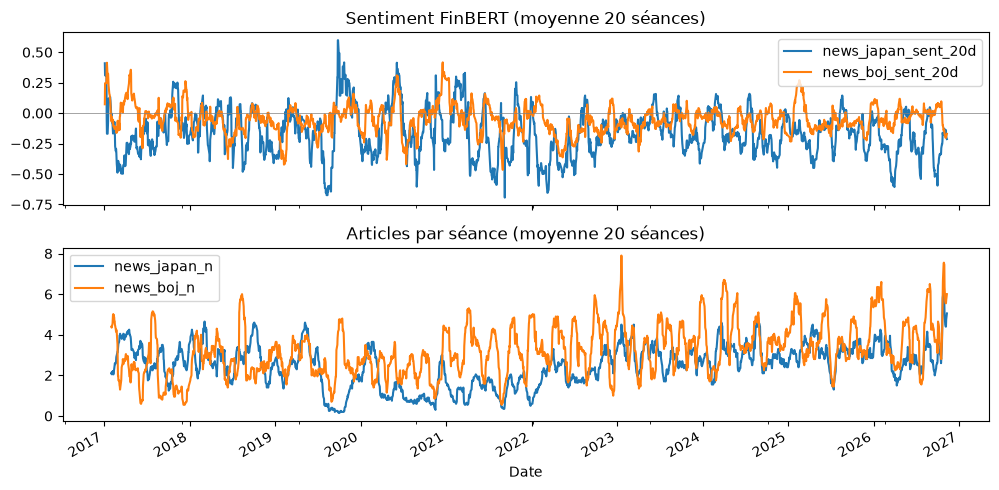

In [13]:
r = n225["n225_close"].pct_change()
ret_today, ret_next = r.reindex(nw.index), r.shift(-1).reindex(nw.index)
for th in THEMES:
    ok = nw[f"news_{th}_n"] > 0                           # séances avec au moins un article du thème
    s = nw.loc[ok, f"news_{th}_sent"]
    print(f"{th:<6} corrélation score de la séance / rendement du jour : {s.corr(ret_today[ok]):+.3f}"
          f"   / rendement du lendemain : {s.corr(ret_next[ok]):+.3f}   ({ok.sum()} séances)")

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
nw[["news_japan_sent_20d", "news_boj_sent_20d"]].plot(ax=ax[0], title="Sentiment FinBERT (moyenne 20 séances)")
ax[0].axhline(0, color="grey", lw=0.5)
nw[["news_japan_n", "news_boj_n"]].rolling(20).mean().plot(ax=ax[1], title="Articles par séance (moyenne 20 séances)")
plt.tight_layout();

## Étape 5 : dataset quotidien complet

1. Indicateurs techniques recalculés (formules du V1) sur le calendrier corrigé, plus le **momentum 3, 6 et 12 mois**
   (63, 126 et 252 séances).
2. Ajout des ETF Japon, du Nikkei VI, des news article par article.
3. Décalage horaire, **amélioré par rapport au V1** :
   - marchés qui ferment **après** Tokyo (S&P 500, VIX, taux US, Bund, MSCI EM, Nifty, Shanghai, USD/JPY, EUR/JPY,
     ETF Japon cotés à New York) : on prend la dernière clôture **de la veille calendaire**. Le V1 décalait d'une
     séance de Tokyo, ce qui faisait perdre les clôtures de New York pendant les jours fériés japonais (le 7 mai 2019,
     après la Golden Week, le V1 utilisait le S&P 500 du 26 avril). Aucune fuite : la clôture de New York de la veille
     a lieu avant l'ouverture de Tokyo ;
   - JGB, TONA, Euribor : une séance de Tokyo (publiés après la clôture) ; €STR : deux séances (publié le lendemain
     matin à Francfort, après la clôture de Tokyo), comme dans le V1.
4. Variables calculées **après** le décalage (elles n'utilisent donc que des valeurs connues) :
   - `smb_etf_ret_1d`, `smb_etf_ret_20d` : rendement des petites capitalisations moins celui du marché japonais ;
   - `carry_1m` $= \dfrac{1 + i^{EUR}/12}{1 + i^{JPY}/12} - 1$ : portage mensuel de la couverture EUR/JPY
     (parité des taux couverte, avec l'€STR et le TONA en %, hypothèse H5) ;
   - `gdelt_<thème>_score` $= \tanh\big((\text{ton}_t - \bar{\text{ton}}_{250}) / \sigma_{250}\big) \in [-1, 1]$ :
     **score de sentiment quotidien complet**. Il s'appuie sur le ton GDELT de *tous* les articles du jour (des centaines),
     alors que FinBERT ne voit qu'environ 4 titres par séance : en quotidien, c'est la variable de sentiment la plus
     fiable ; FinBERT sert surtout en mensuel.

In [14]:
c, h, l = n225["n225_close"], n225["n225_high"], n225["n225_low"]
logret = np.log(c).diff()
tech = pd.DataFrame(index=n225.index)
tech["n225_ret_1d"] = c.pct_change()
for k in (5, 20, 60):
    tech[f"n225_ret_{k}d"] = c.pct_change(k)
for k, m in ((63, 3), (126, 6), (252, 12)):
    tech[f"n225_mom_{m}m"] = c.pct_change(k)
for k in (20, 50, 200):
    tech[f"n225_dist_sma{k}"] = c / c.rolling(k).mean() - 1
tech["n225_vol_20d"] = logret.rolling(20).std() * np.sqrt(252)
tech["n225_vol_ewma"] = np.sqrt((logret ** 2).ewm(alpha=0.06, adjust=False).mean() * 252)   # RiskMetrics, lambda = 0,94
delta = c.diff()
gain = delta.clip(lower=0).ewm(alpha=1/14, adjust=False).mean()
loss = (-delta.clip(upper=0)).ewm(alpha=1/14, adjust=False).mean()
tech["n225_rsi14"] = 100 - 100 / (1 + gain / loss)
macd = c.ewm(span=12, adjust=False).mean() - c.ewm(span=26, adjust=False).mean()
tech["n225_macd"] = macd / c
tech["n225_macd_hist"] = (macd - macd.ewm(span=9, adjust=False).mean()) / c
mid, sd = c.rolling(20).mean(), c.rolling(20).std()
tech["n225_bb_pctb"] = (c - (mid - 2 * sd)) / (4 * sd)
tr = pd.concat([h - l, (h - c.shift()).abs(), (l - c.shift()).abs()], axis=1).max(axis=1)
tech["n225_atr14_pct"] = tr.ewm(alpha=1/14, adjust=False).mean() / c

# Dataset quotidien sur le calendrier corrigé, depuis 2009 (pour que les décalages et les cumuls soient définis en 2010)
base_cols = [x for x in ds.columns if not x.startswith(("n225_", "news_"))]
full = n225[["n225_open", "n225_high", "n225_low", "n225_close", "n225_volume", "n225_volume_missing"]].join(tech)
full = full.join(ds[base_cols])                                       # séries du V1 (2010 -> aujourd'hui)
full = full.join(asof(jp_etf, full.index)) if jp_etf is not None else full
full["nikkei_vi"] = asof(vi_series, full.index) if len(vi_series) else np.nan    # vide avant la 1re valeur
full = full.join(ds.filter(like="news_").add_prefix("gdelt_").rename(columns=lambda x: x.replace("gdelt_news_", "gdelt_")))
full = full.join(nw)
full.index.name = "date"
full.loc[START:].iloc[:, :12].tail(3)

,n225_open,n225_high,n225_low,n225_close,n225_volume,n225_volume_missing,n225_ret_1d,n225_ret_5d,n225_ret_20d,n225_ret_60d,n225_mom_3m,n225_mom_6m
date,,,,,,,,,,,,
2026-11-05,62384.730469,62653.980469,60786.191406,61077.898438,290000000.0,0,-0.017861,-0.044974,-0.135902,-0.078771,-0.051026,0.019367
2026-11-06,60374.351562,60374.351562,56745.808594,57434.769531,314400000.0,0,-0.059647,-0.111735,-0.179922,-0.125580,-0.099132,-0.031208
2026-11-09,57960.699219,59440.179688,57775.160156,58775.500000,314400000.0,1,0.023344,-0.071332,-0.148701,-0.104124,-0.081023,-0.012394


In [15]:
fred_raw = pd.read_csv(RAW / "fred.csv", index_col=0, parse_dates=True)
bund_raw = pd.read_csv(RAW / "bundesbank_bund10y.csv", index_col=0, parse_dates=True)
pick = lambda df, col: df[col].dropna() if df is not None and col in df else pd.Series(dtype=float)

# 1) Marchés qui ferment APRÈS Tokyo : valeur de la dernière clôture de la veille calendaire (J - 1 jour)
CALENDAR_LAG = {
    "sp500": pick(yahoo, "sp500"), "msci_em_eem": pick(yahoo, "msci_em_eem"), "nifty50": pick(yahoo, "nifty50"),
    "shanghai": pick(yahoo, "shanghai"), "eurjpy": pick(yahoo, "eurjpy"),
    "usdjpy": pick(yahoo, "usdjpy_yahoo").combine_first(pick(fred_raw, "usdjpy_fred")),
    "us10y": pick(fred_raw, "us10y").combine_first(pick(yahoo, "us10y_yahoo")),
    "vix": pick(fred_raw, "vix").combine_first(pick(yahoo, "vix_yahoo")),
    "bund10y": pick(bund_raw, "bund10y"),
    **{x: pick(jp_etf, x) for x in JP_ETF.values()},
}
# 2) Séries japonaises publiées après la clôture, et €STR : décalage en séances de Tokyo (comme le V1)
SESSION_LAG = {1: ["jgb2y", "jgb5y", "jgb10y", "jgb30y", "tona", "euribor3m_mavg"], 2: ["eur_overnight"]}

dml = full.copy()
for col, raw in CALENDAR_LAG.items():
    dml[col] = asof(raw, dml.index - pd.Timedelta(days=1)).values if len(raw) else np.nan
for lag, cols in SESSION_LAG.items():
    dml[cols] = dml[cols].shift(lag)
dml["spread_us_jgb10y"] = dml["us10y"] - dml["jgb10y"]
dml["spread_bund_jgb10y"] = dml["bund10y"] - dml["jgb10y"]
LAGS = {"veille calendaire": list(CALENDAR_LAG) + ["spread_us_jgb10y", "spread_bund_jgb10y"],
        "1 séance": SESSION_LAG[1], "2 séances": SESSION_LAG[2]}

# Exemple : lendemain de la Golden Week 2019 (Tokyo fermé du 27/04 au 06/05, New York ouvert)
print("S&P 500 utilisé le 07/05/2019 : V1 =", round(full["sp500"].shift(1).loc["2019-05-07"], 2),
      "(clôture du 26/04)  ->  V2 =", round(dml.loc["2019-05-07", "sp500"], 2), "(clôture du 06/05)")

# Variables calculées après décalage
small, large = dml["msci_japan_small_etf"], dml["msci_japan_etf"]
dml["smb_etf_ret_1d"] = small.pct_change(fill_method=None) - large.pct_change(fill_method=None)
dml["smb_etf_ret_20d"] = small.pct_change(20, fill_method=None) - large.pct_change(20, fill_method=None)
dml["carry_1m"] = (1 + dml["eur_overnight"] / 1200) / (1 + dml["tona"] / 1200) - 1

# GDELT agrégé (V1) : les jours de panne gardent leur ligne, valeur précédente + indicateur
gd = [x for x in dml if x.startswith("gdelt_")]
dml["gdelt_gap"] = dml["gdelt_japan_tone"].isna().astype(int)
dml.loc[dml.index >= NEWS_START, gd] = dml.loc[dml.index >= NEWS_START, gd].ffill()

# Score quotidien complet dans [-1, 1] : ton GDELT de TOUS les articles du jour, comparé à sa moyenne des
# 250 dernières séances (que des valeurs connues à la date t), puis ramené dans [-1, 1] par tanh
for th in ["japan", "boj"]:
    tone = dml[f"gdelt_{th}_tone"]
    mu, sd = tone.rolling(250, min_periods=60).mean(), tone.rolling(250, min_periods=60).std()
    dml[f"gdelt_{th}_score"] = np.tanh((tone - mu) / sd)

# Cibles
dml["target_ret_next_1d"] = dml["n225_close"].shift(-1) / dml["n225_close"] - 1
dml["target_up_next_1d"] = (dml["target_ret_next_1d"] > 0).astype(float).where(dml["target_ret_next_1d"].notna())
dml.loc[START:, ["n225_close", "sp500", "smb_etf_ret_1d", "carry_1m", "news_japan_sent_5d", "target_ret_next_1d"]].tail(3)

S&P 500 utilisé le 07/05/2019 : V1 = 2939.88 (clôture du 26/04)  ->  V2 = 2932.47 (clôture du 06/05)


,n225_close,sp500,smb_etf_ret_1d,carry_1m,news_japan_sent_5d,target_ret_next_1d
date,,,,,,
2026-11-05,61077.898438,7688.620117,0.000875,0.001010,-0.003210,-0.059647
2026-11-06,57434.769531,7353.729980,0.009327,0.001011,-0.580732,0.023344
2026-11-09,58775.500000,7376.859863,-0.006884,0.001011,-0.551463,NaN


### Fichier ML quotidien avec news : aucune séance supprimée

- période : à partir de la première séance où **toutes** les variables de news existent (`gdelt_*_attention` demande
  60 séances, donc fin mars 2017) ;
- colonnes retirées parce qu'elles n'existent pas sur toute la période : elles sont listées ci-dessous (elles restent
  dans `dataset_daily_v2.csv`) ;
- seule la dernière séance est retirée : sa cible (le rendement de demain) n'est pas encore connue.

In [16]:
daily = dml.loc[START:]
news_cols = [x for x in daily if x.startswith("gdelt_")]          # news complètes (GDELT, tous les articles)
first = daily[news_cols].notna().all(axis=1).idxmax()
ml_news = daily.loc[first:].iloc[:-1]
incomplete = ml_news.columns[ml_news.isna().any()]
print("Colonnes retirées (incomplètes sur la période) :")
for x in incomplete:
    fv = daily[x].first_valid_index()
    print(f"  {x:<24} {ml_news[x].isna().sum():>5} cases vides, 1re valeur : {fv.date() if fv is not None else 'pas encore téléchargée'}")
ml_news = ml_news.drop(columns=incomplete)

expected = SESSIONS[(SESSIONS >= ml_news.index[0]) & (SESSIONS <= ml_news.index[-1])]
assert ml_news.index.equals(expected), "des séances manquent"
assert ml_news.isna().sum().sum() == 0
print(f"\ndataset_ml_news_v2 : {ml_news.shape[0]} séances (toutes les séances de Tokyo) x {ml_news.shape[1]} colonnes, "
      f"{ml_news.index[0].date()} -> {ml_news.index[-1].date()}, 0 case vide")

Colonnes retirées (incomplètes sur la période) :
  growth250_etf              205 cases vides, 1re valeur : 2018-01-30
  msci_japan_value_etf       476 cases vides, 1re valeur : 2019-03-08
  nikkei_vi                 1405 cases vides, 1re valeur : 2023-01-04

dataset_ml_news_v2 : 2344 séances (toutes les séances de Tokyo) x 86 colonnes, 2017-03-30 -> 2026-11-06, 0 case vide


## Étape 6 : dataset mensuel (fréquence de la méthode de décision)

Une ligne par mois $t$, datée de la **dernière séance du mois**, avec tout ce qui est connu à sa clôture. Le mois en
cours (pas terminé) est exclu.

### Cibles (mois $t+1$), d'après la partie 1 de la méthode
| Colonne | Formule |
|---|---|
| `target_rn_next` | $R^N_{t+1} = P_{t+1}/P_t - 1$, Nikkei en JPY |
| `target_up_next` | $y_{t+1} = \mathbb{1}\{R^N_{t+1} > 0\}$ |
| `target_fx_next` | $E_{t+1} = S_t / S_{t+1} - 1$, rendement du yen en euros ($S$ = EUR/JPY) |
| `carry_1m` | $C_t = \dfrac{1 + i^{EUR}_t/12}{1 + i^{JPY}_t/12} - 1$ (connu en $t$, ce n'est pas une cible) |
| `target_reur_unhedged_next` | $R_{t+1}(1,0) = R^N + E + R^N E$ |
| `target_reur_hedged_next` | $R_{t+1}(1,1) = R^N + C_t + R^N E$ |
| `target_short_eur_next` | $R_{t+1}(-1) = -R^N(1 + E)$ |

Pour tout autre ratio de couverture : $R_{t+1}(1,h) = R^N + (1-h)E + hC_t + R^N E$, à partir des colonnes ci-dessus.

### Variables explicatives $x_t$ (toutes connues à la fin du mois $t$)
rendements du mois des indices, small − large (ETF, temps réel), Fama-French décalés de 2 mois, variations des taux en
points de base, VIX et Nikkei VI en niveau, CPI et Tankan (dernière publication), momentum 3/6/12 mois, volatilités
réalisées du mois (Nikkei et EUR/JPY), sentiment des news du mois, réunion de la BoJ le mois suivant (calendrier
annoncé un an à l'avance, ce n'est pas une fuite).

In [17]:
month = dml.index.to_period("M")
me = dml.groupby(month).tail(1).index                    # dernière séance de chaque mois
me = me[me.to_period("M") < TODAY.to_period("M")]        # mois terminés uniquement
mp = me.to_period("M")
m = pd.DataFrame(index=me)
m.index.name = "date"

# Nikkei : prix, rendement du mois, momentum, volatilités
P = dml["n225_close"]
m["n225_close"] = P[me]
m["n225_ret_1m"] = m["n225_close"].pct_change()
for k in (3, 6, 12):
    m[f"n225_mom_{k}m"] = m["n225_close"].pct_change(k)
lr = np.log(P).diff()
m["n225_rvol_1m"] = lr.groupby(month).std().reindex(mp).values * np.sqrt(252)
m["n225_vol_ewma"] = dml["n225_vol_ewma"][me]
for x in ["n225_dist_sma200", "n225_rsi14"]:
    m[x] = dml[x][me]

# Rendements du mois des autres marchés (valeurs décalées : connues à la clôture de Tokyo)
for x in ["sp500", "taiex", "shanghai", "nifty50", "msci_em_eem", "topix_etf", "topix_core30_etf",
          "msci_japan_etf", "msci_japan_small_etf", "msci_japan_value_etf", "usdjpy", "eurjpy"]:
    m[f"{x}_ret_1m"] = dml[x][me].pct_change(fill_method=None)
m["smb_etf_1m"] = m["msci_japan_small_etf_ret_1m"] - m["msci_japan_etf_ret_1m"]
m["value_etf_1m"] = m["msci_japan_value_etf_ret_1m"] - m["msci_japan_etf_ret_1m"]
fxr = np.log(dml["eurjpy"]).diff()
m["eurjpy_rvol_1m"] = fxr.groupby(month).std().reindex(mp).values * np.sqrt(252)

# Fama-French Japon, décalés de 2 mois (délai de publication)
if ff is not None:
    ffp = ff.copy()
    ffp.index = ffp.index.to_period("M")
    for x in ["ff_mkt_rf", "ff_smb", "ff_hml"]:
        m[f"{x}_lag2"] = ffp[x].reindex(mp - 2).values

# Taux : niveaux et variations du mois en points de base
for x in ["jgb2y", "jgb10y", "jgb30y", "us10y", "bund10y", "spread_us_jgb10y", "spread_bund_jgb10y", "tona", "eur_overnight"]:
    m[x] = dml[x][me]
    m[f"d_{x}_bp"] = m[x].diff() * 100
m["carry_1m"] = dml["carry_1m"][me]

# Volatilité, macro (dernière publication connue)
for x in ["vix", "nikkei_vi", "cpi_all_yoy", "cpi_core_yoy", "cpi_corecore_yoy",
          "tankan_large_manuf", "tankan_large_nonmanuf", "tankan_large_manuf_fcst", "pmi_manuf"]:
    if x in dml:
        m[x] = dml[x][me]
m["d_vix"] = m["vix"].diff()

# BoJ : réunion prévue le mois suivant
cal = pd.read_csv(RAW / "boj_calendar.csv", index_col=0, parse_dates=True)
meet = pd.Series(1, index=cal.index.to_period("M")).groupby(level=0).sum()
m["boj_meeting_next_month"] = meet.reindex(mp + 1, fill_value=0).values

# News du mois : moyenne des scores de tous les articles rattachés aux séances du mois
art["month"] = art["session"].dt.to_period("M")
for th in THEMES:
    g = art[art["theme"] == th].groupby("month")
    m[f"news_{th}_sent_1m"] = g["score"].mean().reindex(mp).values
    m[f"news_{th}_n_1m"] = g["score"].size().reindex(mp).values
    m[f"news_{th}_neg_share_1m"] = g["p_neg"].apply(lambda x: (x > 0.5).mean()).reindex(mp).values
    m[f"d_news_{th}_sent_1m"] = m[f"news_{th}_sent_1m"].diff()
for x in ["gdelt_japan_tone", "gdelt_boj_tone", "gdelt_japan_share", "gdelt_boj_share"]:
    m[f"{x}_1m"] = full[x].groupby(full.index.to_period("M")).mean().reindex(mp).values
for th in ["japan", "boj"]:     # moyenne mensuelle du score quotidien GDELT, si au moins 10 séances valides
    g = dml[f"gdelt_{th}_score"].groupby(month)
    m[f"gdelt_{th}_score_1m"] = g.mean().where(g.count() >= 10).reindex(mp).values
m["news_gap_days_1m"] = nw["news_gap"].groupby(nw.index.to_period("M")).sum().reindex(mp).values

# Cibles
S = full["eurjpy"][me]                                    # EUR/JPY non décalé, fin de mois
rn = m["n225_close"].shift(-1) / m["n225_close"] - 1
E = S / S.shift(-1) - 1
m["target_rn_next"] = rn
m["target_up_next"] = (rn > 0).astype(float).where(rn.notna())
m["target_fx_next"] = E
m["target_reur_unhedged_next"] = rn + E + rn * E
m["target_reur_hedged_next"] = rn + m["carry_1m"] + rn * E
m["target_short_eur_next"] = -rn * (1 + E)
m = m.loc[START:]
print(f"dataset_monthly : {m.shape[0]} mois x {m.shape[1]} colonnes, {m.index[0].date()} -> {m.index[-1].date()}")
m[["n225_ret_1m", "n225_mom_12m", "smb_etf_1m", "ff_hml_lag2", "carry_1m", "news_japan_sent_1m", "target_rn_next", "target_reur_hedged_next"]].tail(4)

dataset_monthly : 202 mois x 77 colonnes, 2010-01-29 -> 2026-10-30


,n225_ret_1m,n225_mom_12m,smb_etf_1m,ff_hml_lag2,carry_1m,news_japan_sent_1m,target_rn_next,target_reur_hedged_next
date,,,,,,,,
2026-07-31,-0.081360,0.567137,0.005869,0.0157,0.001004,-0.308652,0.030296,0.031141
2026-08-31,0.030296,0.552301,-0.000550,0.0069,0.001008,0.026382,0.006662,0.007934
2026-09-30,0.006662,0.485640,-0.011257,0.0554,0.001010,-0.616487,-0.051886,-0.051476
2026-10-30,-0.051886,0.207565,-0.000763,0.0049,0.001009,-0.127580,NaN,NaN


### Fichier mensuel prêt pour le ML : depuis 2017, avec news, aucune case vide

Même règle que pour le quotidien : on garde toutes les lignes depuis le premier mois où les news existent ; les
colonnes incomplètes sur la période sont retirées (et listées) ; le dernier mois est retiré car sa cible n'est pas
encore connue (c'est la ligne à prédire, elle reste dans `dataset_monthly.csv`).

⚠️ **Taille de l'échantillon** : environ 115 mois. C'est peu pour un gradient boosting ou un réseau de neurones :
garde peu de variables (présélection par le volet 1), régularise, et compare toujours à la régression logistique.

In [18]:
news_m = [x for x in m if x.startswith("gdelt_")]                # news complètes (GDELT)
complete_news = m[news_m].notna().all(axis=1)
assert complete_news.any(), "aucun mois avec toutes les news : relance l'étape 3 (téléchargement GDELT)"
mn = m.loc[complete_news.idxmax():].iloc[:-1]                    # 1er mois où toutes les news existent
inc = mn.columns[mn.isna().any()]
print("Colonnes retirées (incomplètes depuis 2017) :")
for x in inc:
    fv = m[x].first_valid_index()
    print(f"  {x:<28} {mn[x].isna().sum():>3} mois vides, 1re valeur : {fv.date() if fv is not None else 'jamais'}")
mn = mn.drop(columns=inc)
assert mn.isna().sum().sum() == 0
print(f"\ndataset_monthly_ml : {mn.shape[0]} mois x {mn.shape[1]} colonnes, {mn.index[0].date()} -> {mn.index[-1].date()}, 0 case vide")
print(f"Mois à prédire (dernière ligne de dataset_monthly.csv) : {m.index[-1].date()}")

Colonnes retirées (incomplètes depuis 2017) :
  msci_japan_value_etf_ret_1m   24 mois vides, 1re valeur : 2019-04-26
  value_etf_1m                  24 mois vides, 1re valeur : 2019-04-26
  nikkei_vi                     69 mois vides, 1re valeur : 2023-01-31

dataset_monthly_ml : 114 mois x 74 colonnes, 2017-04-28 -> 2026-09-30, 0 case vide
Mois à prédire (dernière ligne de dataset_monthly.csv) : 2026-10-30


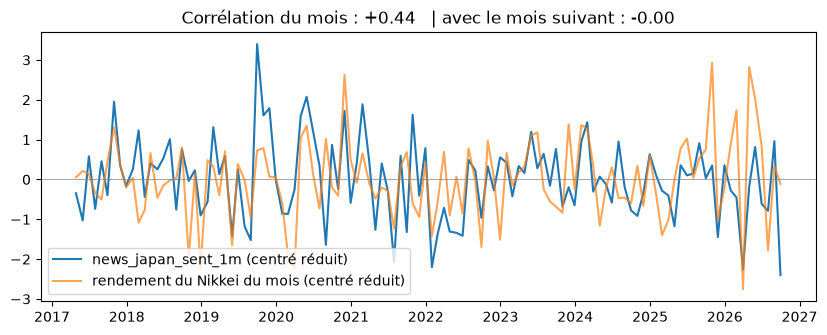

In [19]:
fig, ax = plt.subplots(figsize=(10, 3.5))
z = lambda s: (s - s.mean()) / s.std()
sc = "news_japan_sent_1m" if "news_japan_sent_1m" in mn else "gdelt_japan_score_1m"   # FinBERT si complet, sinon GDELT
ax.plot(mn.index, z(mn[sc]), label=f"{sc} (centré réduit)")
ax.plot(mn.index, z(mn["n225_ret_1m"]), label="rendement du Nikkei du mois (centré réduit)", alpha=0.7)
ax.axhline(0, color="grey", lw=0.5)
ax.legend(loc="lower left")
ax.set_title(f"Corrélation du mois : {mn[sc].corr(mn['n225_ret_1m']):+.2f}   "
             f"| avec le mois suivant : {mn[sc].corr(mn['target_rn_next']):+.2f}");

## Étape 7 : contrôles qualité

- Aucune séance de Tokyo ne manque dans le fichier quotidien (vérifié par `assert` plus haut).
- **Couverture des news** : nombre d'articles par mois. ⚠️ Le volume total suivi par GDELT baisse fortement depuis 2023,
  et encore plus depuis octobre 2026 (moins de 100 articles par jour pour le thème Japon début novembre 2026, contre plus
  de 1 000 en 2017-2020). Les derniers mois sont donc moins fiables : `news_gap` et `news_gap_days_1m` le signalent.

In [20]:
cov = art.groupby([art["session"].dt.to_period("Q"), "theme"]).size().unstack()
cov["séances sans article"] = nw["news_gap"].groupby(nw.index.to_period("Q")).sum()
cov.tail(12)

theme,boj,japan,séances sans article
session,,,
2024Q1,203,190,2
2024Q2,238,190,1
2024Q3,224,196,1
2024Q4,243,170,0
2025Q1,233,190,0
2025Q2,228,188,10
2025Q3,231,196,4
2025Q4,236,197,0
2026Q1,236,183,2


## Étape 8 : sauvegarde et dictionnaire des variables

In [21]:
def describe(col):
    rules = [
        (r"^target_rn_next$", "Rendement du Nikkei 225 en JPY sur le mois suivant (P_{t+1}/P_t - 1)"),
        (r"^target_up_next$", "1 si le Nikkei monte le mois suivant, 0 sinon"),
        (r"^target_fx_next$", "Rendement du yen exprimé en euros sur le mois suivant : S_t/S_{t+1} - 1"),
        (r"^target_reur_unhedged_next$", "Rendement en EUR d'une position longue Nikkei non couverte (h = 0)"),
        (r"^target_reur_hedged_next$", "Rendement en EUR d'une position longue Nikkei couverte à 100 % (h = 1)"),
        (r"^target_short_eur_next$", "Rendement en EUR d'une position vendeuse (future Nikkei, marge en EUR)"),
        (r"^target_ret_next_1d$", "Rendement du Nikkei de la clôture t à la clôture t+1"),
        (r"^target_up_next_1d$", "1 si le Nikkei monte le lendemain"),
        (r"^carry_1m$", "Portage mensuel de la couverture EUR/JPY : (1+i_EUR/12)/(1+i_JPY/12) - 1 (€STR, TONA)"),
        (r"^n225_mom_(\d+)m$", r"Momentum du Nikkei sur \1 mois : P_t / P_{t-k} - 1"),
        (r"^n225_rvol_1m$", "Volatilité réalisée du Nikkei sur le mois (écart-type des rendements log quotidiens, annualisé)"),
        (r"^n225_vol_ewma$", "Volatilité EWMA du Nikkei (lambda = 0,94), annualisée"),
        (r"^eurjpy_rvol_1m$", "Volatilité réalisée de l'EUR/JPY sur le mois, annualisée"),
        (r"^smb_etf_1m$", "Small - large Japon du mois : rendement SCJ - rendement EWJ (temps réel)"),
        (r"^smb_etf_ret_(\d+)d$", r"Small - large Japon sur \1 jour(s) : rendement SCJ - rendement EWJ"),
        (r"^value_etf_1m$", "Value - marché Japon du mois : rendement EWJV - rendement EWJ (depuis 2019)"),
        (r"^ff_(\w+)_lag2$", r"Facteur Fama-French Japon \1 du mois t-2 (délai de publication)"),
        (r"^d_(\w+)_bp$", r"Variation sur le mois de \1, en points de base"),
        (r"^d_vix$", "Variation du VIX sur le mois"),
        (r"^(\w+)_ret_1m$", r"Rendement de \1 sur le mois"),
        (r"^news_(\w+)_sent_1m$", r"Score FinBERT moyen des articles du thème \1 sur le mois, dans [-1, 1]"),
        (r"^d_news_(\w+)_sent_1m$", r"Variation du score FinBERT mensuel du thème \1"),
        (r"^news_(\w+)_n_1m$", r"Nombre d'articles du thème \1 sur le mois (plafond GDELT : 250 par semaine)"),
        (r"^news_(\w+)_neg_share_1m$", r"Part des articles du thème \1 avec P(négatif) > 0,5 sur le mois"),
        (r"^news_(\w+)_sent$", r"Score FinBERT moyen des articles du thème \1 rattachés à la séance, dans [-1, 1]"),
        (r"^news_(\w+)_sent_(\d+)d$", r"Score FinBERT moyen du thème \1 sur \2 séances, pondéré par le nombre d'articles"),
        (r"^news_(\w+)_neg_share_5d$", r"Part des articles du thème \1 avec P(négatif) > 0,5 sur 5 séances"),
        (r"^news_(\w+)_n$", r"Nombre d'articles du thème \1 rattachés à la séance"),
        (r"^news_gap$", "1 si aucun article GDELT pour la séance (panne) : scores repris des séances précédentes"),
        (r"^news_gap_days_1m$", "Nombre de séances sans article dans le mois"),
        (r"^gdelt_(\w+)_score_1m$", r"Score de sentiment mensuel \1 dans [-1, 1] : moyenne du score quotidien GDELT sur le mois"),
        (r"^gdelt_(\w+)_1m$", r"Moyenne mensuelle de la série GDELT agrégée \1 (V1)"),
        (r"^gdelt_(\w+)_score$", r"Score quotidien \1 dans [-1, 1] : tanh du ton GDELT de tous les articles du jour, centré-réduit sur 250 séances"),
        (r"^gdelt_gap$", "1 si la série GDELT agrégée manquait ce jour (valeur précédente reprise)"),
        (r"^gdelt_(\w+)$", r"Série GDELT agrégée du V1 : \1 (ton de -10 à +10, share = articles pour 10 000, attention = z-score 60 séances)"),
        (r"^boj_meeting_next_month$", "Nombre de réunions de politique monétaire de la BoJ prévues le mois suivant"),
        (r"^n225_volume_missing$", "1 si le volume du Nikkei manquait chez Yahoo (remplacé par la veille)"),
        (r"^nikkei_vi$", "Nikkei Stock Average Volatility Index (officiel depuis 2023, manuel avant)"),
        (r"^msci_japan_etf$", "ETF iShares MSCI Japan (EWJ), USD"),
        (r"^msci_japan_small_etf$", "ETF iShares MSCI Japan Small-Cap (SCJ), USD"),
        (r"^msci_japan_value_etf$", "ETF iShares MSCI Japan Value (EWJV), USD, depuis 2019"),
        (r"^n225_(open|high|low|close|volume)$", r"Nikkei 225 : \1 (Yahoo ^N225)"),
        (r"^n225_ret_(\d+)d$", r"Rendement du Nikkei sur \1 séance(s)"),
        (r"^n225_dist_sma(\d+)$", r"Écart du Nikkei à sa moyenne mobile \1 séances : close / SMA - 1"),
        (r"^n225_vol_20d$", "Volatilité réalisée du Nikkei sur 20 séances, annualisée"),
        (r"^n225_rsi14$", "RSI de Wilder 14 séances"),
        (r"^n225_macd(_hist)?$", r"MACD (12, 26, 9)\1 divisé par le prix"),
        (r"^n225_bb_pctb$", "Position dans les bandes de Bollinger (20 j, 2 sigma)"),
        (r"^n225_atr14_pct$", "Average True Range 14 j divisé par le prix"),
        (r"^(sp500|taiex|shanghai|nifty50)$", r"Indice \1, clôture (Yahoo)"),
        (r"^msci_em_eem$", "ETF EEM, proxy du MSCI Emerging Markets (USD)"),
        (r"^(topix_etf|topix_core30_etf)$", r"ETF \1 (1306.T / 1311.T), proxy du TOPIX / Core30, corrigé des erreurs d'échelle"),
        (r"^(usdjpy|eurjpy)$", r"Taux de change \1 (yens pour une unité de devise)"),
        (r"^(us10y|bund10y)$", r"Rendement à 10 ans \1, en %"),
        (r"^jgb(\d+)y$", r"Rendement JGB \1 ans, en % (MOF)"),
        (r"^vix$", "VIX (CBOE), niveau"),
        (r"^tona$", "TONA, taux au jour le jour du yen, en % (BoJ)"),
        (r"^eur_overnight$", "Taux au jour le jour de l'euro, en % (EONIA puis €STR)"),
        (r"^euribor3m_mavg$", "Euribor 3 mois, moyenne mensuelle, en %"),
        (r"^tankan_(\w+)$", r"Tankan, DI des grandes entreprises : \1 (dernière publication)"),
        (r"^cpi_(\w+)$", r"CPI Japon : \1 (dernière publication, e-Stat)"),
        (r"^spread_(\w+)$", r"Écart de taux \1, en points de %"),
        (r"^boj_(\w+)$", r"Calendrier BoJ : \1"),
    ]
    for pat, text in rules:
        if re.match(pat, col):
            return re.sub(pat, text, col)
    return "Variable du V1 (voir 00a_collecte_V1.ipynb)"

lag_of = {x: lag for lag, cols in LAGS.items() for x in cols}
dico = []
for fname, df, freq in [("dataset_ml_news_v2.csv", ml_news, "quotidien"), ("dataset_monthly_ml.csv", mn, "mensuel")]:
    for x in df.columns:
        dico.append(dict(fichier=fname, colonne=x, frequence=freq, decalage=lag_of.get(x, "aucun (connu avant la clôture)"),
                         cible=x.startswith("target_"), definition=describe(x)))
dico = pd.DataFrame(dico)

art_out = art[["session", "seendate", "theme", "title", "domain", "sourcecountry", "url", "p_pos", "p_neg", "p_neu", "score"]]
art_out = art_out.replace({"domain": {"": np.nan}, "sourcecountry": {"": np.nan}}).fillna({"domain": "inconnu", "sourcecountry": "inconnu"})
art_out.sort_values(["session", "seendate"]).to_csv(DATA / "news_articles.csv", index=False, float_format="%.4f")
full.loc[START:].to_csv(DATA / "dataset_daily_v2.csv", float_format="%.6g")
ml_news.to_csv(DATA / "dataset_ml_news_v2.csv", float_format="%.6g")
m.to_csv(DATA / "dataset_monthly.csv", float_format="%.6g")
mn.to_csv(DATA / "dataset_monthly_ml.csv", float_format="%.6g")
dico.to_csv(DATA / "dictionnaire_variables.csv", index=False)

for f in ["news_articles.csv", "dataset_daily_v2.csv", "dataset_ml_news_v2.csv", "dataset_monthly.csv",
          "dataset_monthly_ml.csv", "dictionnaire_variables.csv"]:
    d = pd.read_csv(DATA / f, low_memory=False)
    print(f"{f:<28} {d.shape[0]:>7} lignes x {d.shape[1]:>3} colonnes   cases vides : {d.isna().sum().sum()}")

news_articles.csv              13694 lignes x  11 colonnes   cases vides : 0
dataset_daily_v2.csv            4118 lignes x  82 colonnes   cases vides : 40322
dataset_ml_news_v2.csv          2344 lignes x  87 colonnes   cases vides : 0
dataset_monthly.csv              202 lignes x  78 colonnes   cases vides : 1662
dataset_monthly_ml.csv           114 lignes x  75 colonnes   cases vides : 0
dictionnaire_variables.csv       160 lignes x   6 colonnes   cases vides : 0


In [22]:
# Pour charger les fichiers dans un autre notebook :
# daily   = pd.read_csv("../data/2_construites/dataset_ml_news_v2.csv", index_col="date", parse_dates=True)
# monthly = pd.read_csv("../data/2_construites/dataset_monthly_ml.csv", index_col="date", parse_dates=True)
# news    = pd.read_csv("../data/2_construites/news_articles.csv", parse_dates=["session", "seendate"])